# Cuando la varianza y la física no están alineadas

**Pregunta.** ¿Qué ocurre si una dirección de baja varianza de las entradas sigue siendo necesaria para representar la solución de la ecuación?

Este control sintético de advección en dimensión 20 compara la PINN base con PCA de entrada al 99% (\(k=3\)) y con PCA fijado en \(k=4\). La solución depende de una dirección de alta varianza y de \(q_4\), situada por debajo del umbral de 99%. Así, PCA al 99% elimina una coordenada físicamente activa, mientras que \(k=4\) la conserva.

## Diseño empírico

La ecuación probada es \(u_t + v^\top \nabla_x u=0\) en \(\mathbb R^{20}\). La distribución de coordenadas es gaussiana con autovalores de covarianza \(0.2^j\). La solución exacta usa \(q_1\) y \(q_4\); la frecuencia de \(q_4\) se escala por la inversa de su desviación estándar para que su variación observada tenga magnitud comparable.

- Diez semillas, mismas coordenadas, particiones temporales, minibatches, condiciones iniciales y puntos de residuo por semilla.
- Redes con cantidades de parámetros emparejadas (diferencia máxima permitida: 5%).
- PCA centrado se ajusta solo con coordenadas de entrenamiento. La proyección es lineal y JAX autodiferencia hasta las coordenadas originales.
- Se presentan presupuestos de 2000 y 5000 pasos, regenerados con la misma versión del código. Cada corrida reinicia el entrenamiento desde la misma inicialización por semilla y conserva el mismo protocolo de muestreo; solo cambia el presupuesto.

Este es un caso sintético controlado para evaluar sensibilidad a la alineación entre varianza y relevancia física; no basta por sí solo para generalizar a otras ecuaciones o distribuciones.

In [1]:
from pathlib import Path
import csv
import json
import math
from IPython.display import display, HTML, Markdown, SVG

ROOT = Path.cwd()
while not (ROOT / 'pyproject.toml').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
RUNS = {
    2000: ROOT / 'results/high_dimensional_advection/alignment_sensitivity/low_variance_active_direction_d20_10_seeds_2k_current_v1',
    5000: ROOT / 'results/high_dimensional_advection/alignment_sensitivity/low_variance_active_direction_d20_10_seeds_5k_v1',
}
for steps, path in RUNS.items():
    if not (path / 'summary.json').exists():
        raise FileNotFoundError(f'Faltan los resultados de {steps} pasos: {path}')

def read_csv(path):
    with path.open(newline='', encoding='utf-8') as f:
        return list(csv.DictReader(f))

RESULTS = {steps: json.loads((path / 'summary.json').read_text(encoding='utf-8'))
           for steps, path in RUNS.items()}
METRICS = {steps: read_csv(path / 'metrics.csv') for steps, path in RUNS.items()}
TRAJECTORIES = {steps: read_csv(path / 'validation_trajectories.csv')
               for steps, path in RUNS.items()}
print('Resultados cargados:', {steps: len(rows) for steps, rows in METRICS.items()}, 'corridas')

Resultados cargados: {2000: 30, 5000: 30} corridas


## Resultados finales por presupuesto

La tabla reporta media ± desviación estándar entre semillas. El tiempo de pipeline incluye el ajuste de PCA en los modelos reducidos. El error L2 y el residuo PDE se evalúan en los mismos datos de prueba para las tres variantes.

In [2]:
MODELS = ['PINN base', 'PCA input 99%', 'PCA input k=4']
METRIC_LABELS = [
    ('test_relative_l2', 'Error relativo L2'),
    ('test_pde_residual_rms', 'Residuo PDE RMS'),
    ('pipeline_seconds', 'Tiempo pipeline (s)'),
]

def mean_std(values):
    values = [float(v) for v in values if v not in ('', 'None', None)]
    mean = sum(values) / len(values)
    sd = math.sqrt(sum((v - mean) ** 2 for v in values) / (len(values) - 1)) if len(values) > 1 else 0.0
    return f'{mean:.4f} ± {sd:.4f}'

table_rows = []
for steps in (2000, 5000):
    records = METRICS[steps]
    for model in MODELS:
        subset = [r for r in records if r['model'] == model]
        k_values = sorted({r['k'] for r in subset if r['k'] not in ('', 'None')})
        retained = [float(r['retained_variance']) for r in subset if r['retained_variance'] not in ('', 'None')]
        table_rows.append([steps, model, ', '.join(k_values) or '—',
            f'{100*sum(retained)/len(retained):.3f}%' if retained else '—',
            *[mean_std([r[key] for r in subset]) for key, _ in METRIC_LABELS]])
headers = ['Pasos', 'Modelo', 'k', 'Varianza retenida', *[label for _, label in METRIC_LABELS]]
display(HTML('<table><thead><tr>' + ''.join(f'<th>{h}</th>' for h in headers) + '</tr></thead><tbody>' +
             ''.join('<tr>' + ''.join(f'<td>{v}</td>' for v in row) + '</tr>' for row in table_rows) +
             '</tbody></table>'))

Pasos,Modelo,k,Varianza retenida,Error relativo L2,Residuo PDE RMS,Tiempo pipeline (s)
2000,PINN base,—,—,0.5221 ± 0.0162,0.0486 ± 0.0105,4.3164 ± 1.1270
2000,PCA input 99%,3,99.218%,0.5259 ± 0.0090,0.0429 ± 0.0063,4.2523 ± 1.0000
2000,PCA input k=4,4,99.843%,0.5289 ± 0.0238,0.0445 ± 0.0080,4.5737 ± 1.2466
5000,PINN base,—,—,0.4679 ± 0.1125,0.0435 ± 0.0116,11.9990 ± 3.2625
5000,PCA input 99%,3,99.218%,0.5045 ± 0.0142,0.0452 ± 0.0073,12.6577 ± 3.9472
5000,PCA input k=4,4,99.843%,0.2310 ± 0.1529,0.0232 ± 0.0131,13.1652 ± 3.8256


## Comparación pareada contra la PINN base

Cada diferencia se calcula dentro de la misma semilla. Para error, residuo y tiempo, un valor negativo favorece PCA. La columna de conteo muestra en cuántas de las diez semillas PCA obtuvo un valor menor que la base.

In [3]:
PAIR_METRICS = [('test_relative_l2', 'Δ error L2'),
                ('test_pde_residual_rms', 'Δ residuo PDE'),
                ('pipeline_seconds', 'Δ tiempo pipeline (s)')]
paired_rows = []
for steps in (2000, 5000):
    records = METRICS[steps]
    by_seed = {(r['model'], int(r['seed'])): r for r in records}
    for model in MODELS[1:]:
        row = [steps, model]
        for key, _ in PAIR_METRICS:
            delta = [float(by_seed[(model, s)][key]) - float(by_seed[('PINN base', s)][key])
                     for s in sorted({int(r['seed']) for r in records})]
            row.extend([mean_std(delta), f'{sum(d < 0 for d in delta)}/10'])
        paired_rows.append(row)
headers = ['Pasos', 'Modelo'] + [item for _, label in PAIR_METRICS for item in (label + ' media ± DE', 'PCA menor')]
display(HTML('<table><thead><tr>' + ''.join(f'<th>{h}</th>' for h in headers) + '</tr></thead><tbody>' +
             ''.join('<tr>' + ''.join(f'<td>{v}</td>' for v in row) + '</tr>' for row in paired_rows) +
             '</tbody></table>'))

Pasos,Modelo,Δ error L2 media ± DE,PCA menor,Δ residuo PDE media ± DE,PCA menor,Δ tiempo pipeline (s) media ± DE,PCA menor
2000,PCA input 99%,0.0037 ± 0.0132,5/10,-0.0057 ± 0.0100,6/10,-0.0640 ± 0.8319,4/10
2000,PCA input k=4,0.0067 ± 0.0144,5/10,-0.0041 ± 0.0104,7/10,0.2574 ± 1.6870,4/10
5000,PCA input 99%,0.0366 ± 0.1052,3/10,0.0017 ± 0.0097,5/10,0.6587 ± 0.9983,3/10
5000,PCA input k=4,-0.2369 ± 0.1805,8/10,-0.0204 ± 0.0128,9/10,1.1661 ± 2.9024,4/10


## ¿Qué muestra la validación al aumentar el presupuesto?

La siguiente tabla resume la RMSE de validación en checkpoints comunes. Las corridas se reinician con la misma semilla y protocolo. La celda posterior compara las trayectorias hasta 2000 pasos: si no coinciden exactamente, se informa y se interpreta el presupuesto extendido como repetición pareada, no como continuación de un checkpoint guardado. Si \(k=4\) mejora respecto a \(k=3\) al extender el entrenamiento, la señal inicial es compatible con falta de presupuesto. Si permanecen similares, este experimento no demuestra que la dirección omitida sea prescindible; solo indica que esta configuración no logró explotar su inclusión.

In [4]:
checkpoints = [1000, 2000, 3000, 4000, 5000]
curve_rows = []
for steps in (2000, 5000):
    by_group = {}
    for r in TRAJECTORIES[steps]:
        step = int(r['step'])
        if step in checkpoints:
            by_group.setdefault((r['model'], step), []).append(float(r['validation_rmse']))
    for model in MODELS:
        for step in checkpoints:
            values = by_group.get((model, step), [])
            if values:
                curve_rows.append([steps, model, step, mean_std(values)])
display(HTML('<table><thead><tr><th>Corrida</th><th>Modelo</th><th>Paso</th><th>RMSE validación, media ± DE</th></tr></thead><tbody>' +
             ''.join('<tr>' + ''.join(f'<td>{v}</td>' for v in row) + '</tr>' for row in curve_rows) +
             '</tbody></table>'))

Corrida,Modelo,Paso,"RMSE validación, media ± DE"
2000,PINN base,1000,0.4313 ± 0.0151
2000,PINN base,2000,0.4078 ± 0.0094
2000,PCA input 99%,1000,0.4311 ± 0.0206
2000,PCA input 99%,2000,0.4095 ± 0.0149
2000,PCA input k=4,1000,0.4308 ± 0.0180
2000,PCA input k=4,2000,0.4100 ± 0.0158
5000,PINN base,1000,0.4313 ± 0.0151
5000,PINN base,2000,0.4078 ± 0.0094
5000,PINN base,3000,0.3989 ± 0.0107
5000,PINN base,4000,0.3779 ± 0.0677


In [5]:
# Compara los prefijos de validación. Una diferencia no nula se reporta, no se oculta.
def trajectory_map(rows):
    return {(r['model'], int(r['seed']), int(r['step'])): float(r['validation_rmse'])
            for r in rows if int(r['step']) <= 2000}
short = trajectory_map(TRAJECTORIES[2000])
long = trajectory_map(TRAJECTORIES[5000])
shared = sorted(set(short) & set(long))
max_difference = max((abs(short[key] - long[key]) for key in shared), default=float('nan'))
print(f'Puntos de validación comparables: {len(shared)}; diferencia absoluta máxima entre prefijos: {max_difference:.3e}')

Puntos de validación comparables: 600; diferencia absoluta máxima entre prefijos: 0.000e+00


## Figuras de la corrida extendida

Las métricas de prueba corresponden a las mismas particiones pareadas por semilla. Las curvas de validación se incluyen para mostrar la trayectoria completa de optimización.

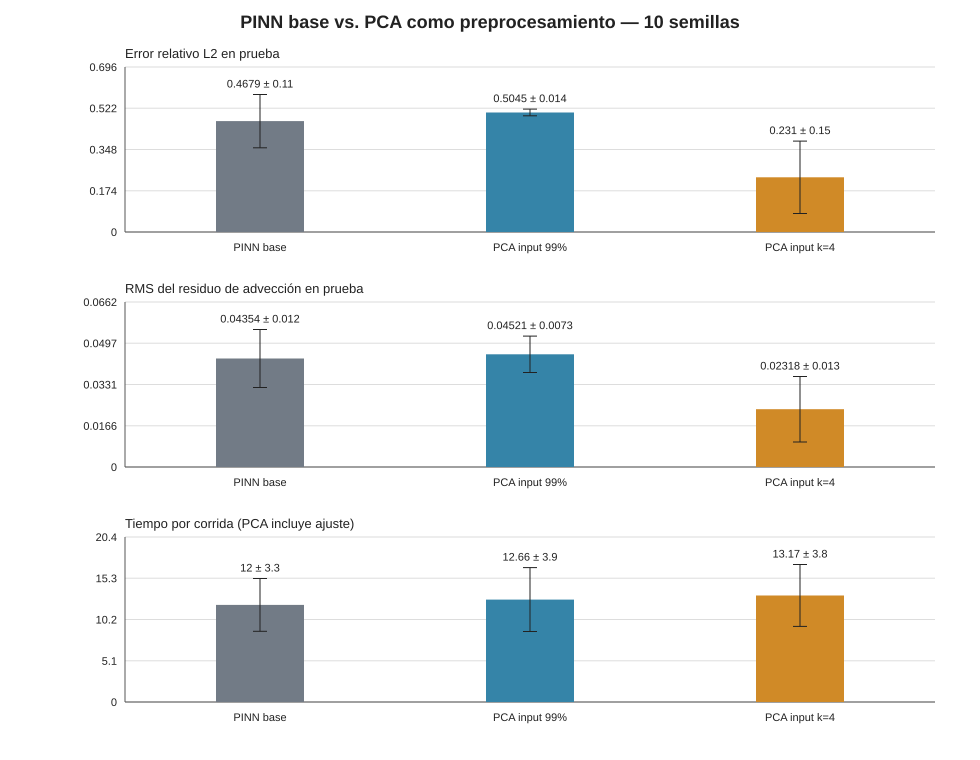

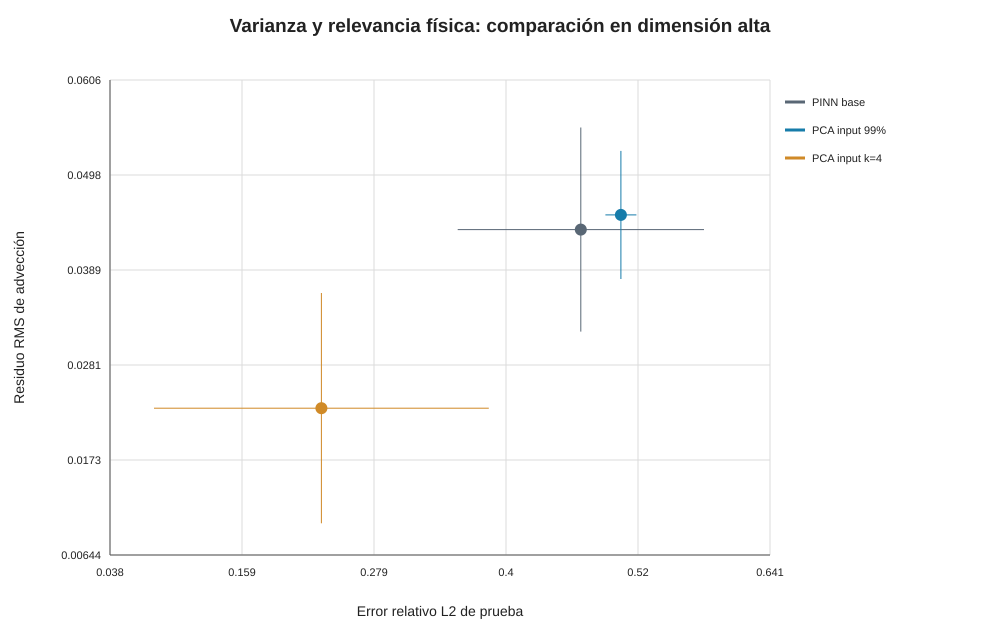

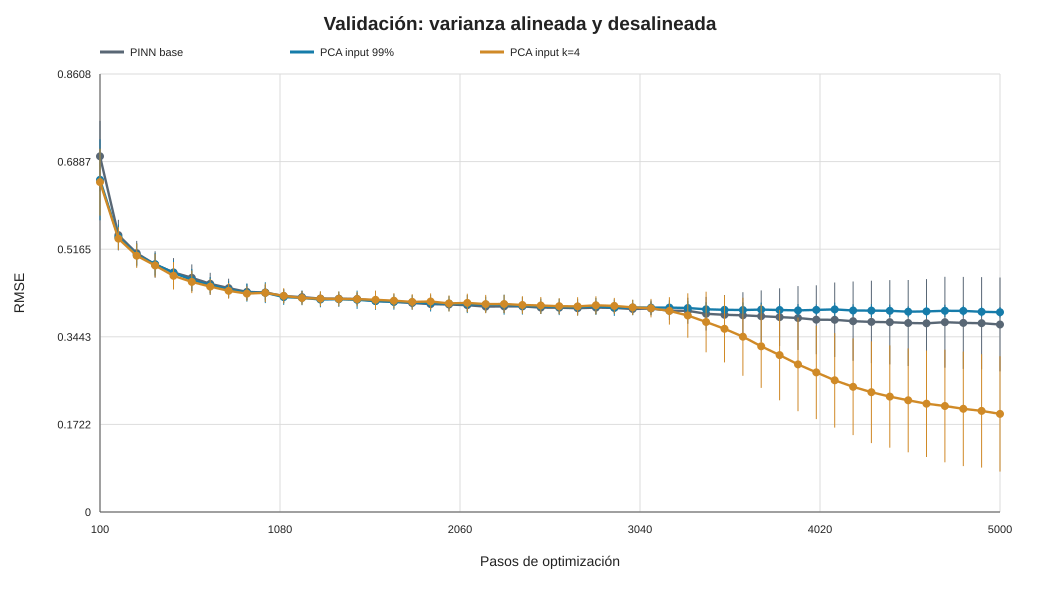

In [6]:
for filename in ('comparison.svg', 'error_residual_tradeoff.svg', 'validation_rmse_vs_steps.svg'):
    display(SVG(filename=str(RUNS[5000] / filename)))

## Lectura y alcance

En 2000 pasos, las tres variantes quedan cerca en error de prueba (L2: 0.522 base, 0.526 con PCA al 99% y 0.529 con \(k=4\)). A 5000 pasos, PCA con \(k=4\) baja el error L2 medio a 0.231 ± 0.153 y el residuo RMS a 0.0232 ± 0.0131; mejora frente a la base en 8/10 semillas para L2 y 9/10 para residuo. PCA al 99% no replica esa mejora (L2 medio 0.505 frente a 0.468 de la base).

El resultado apoya, para este caso sintético y con 5000 pasos, que conservar \(q_4\) facilita aprender la solución. No muestra reducción de tiempo: el pipeline de \(k=4\) tarda en promedio 1.17 s más que la base (DE pareada 2.90 s; fue más rápido en 4/10 semillas). La variabilidad entre semillas de \(k=4\) es alta, así que conviene leer las métricas junto con las curvas y no presentar la media como una garantía.

La conclusión se limita a esta distribución, solución, arquitectura y presupuesto. No se selecciona \(k\) con el conjunto de prueba; el número de componentes está fijado por el umbral de varianza o por el control predefinido \(k=4\).